# Vadodara Flood EWS: EDA and model comparison
**All water levels here are SYNTHETIC-TARGET** (see `data/processed/dataset_card.json`).

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(9,3.2)
df = pd.read_parquet('../data/processed/flood_dataset.parquet')
card = json.load(open('../data/processed/dataset_card.json'))
print(card['mode']); print(json.dumps(card['labels'], indent=1)); print(df.shape)

SYNTHETIC_RAIN__SYNTHETIC_TARGET
{
 "rain_mmh": "SYNTHETIC",
 "soil_moisture": "DERIVED from SYNTHETIC rain",
 "discharge_upstream": "DERIVED from SYNTHETIC rain (index units)",
 "level_cm and level_in_*h": "SYNTHETIC-TARGET (physics sim driven by rain + injected sensor faults)",
 "flood_in_3h": "DERIVED from the SYNTHETIC-TARGET level and config danger_cm",
 "fc_rain_*": "DERIVED/SYNTHETIC (noisy copy of future rain; 25% rows masked)"
}
(405031, 38)


## Cleaning report (spikes, gaps, duplicates)

In [2]:
pd.DataFrame(card['cleaning_report']).T

,rows_in,duplicates_removed,missing_hours_before,level_spikes_removed,rain_outliers_removed,missing_hours_after
akota,139357,70,969,106,0,782
alkapuri,139287,70,1039,110,0,851
kamnath,139303,70,1023,83,0,837


## Rainfall: annual total and monsoon seasonality

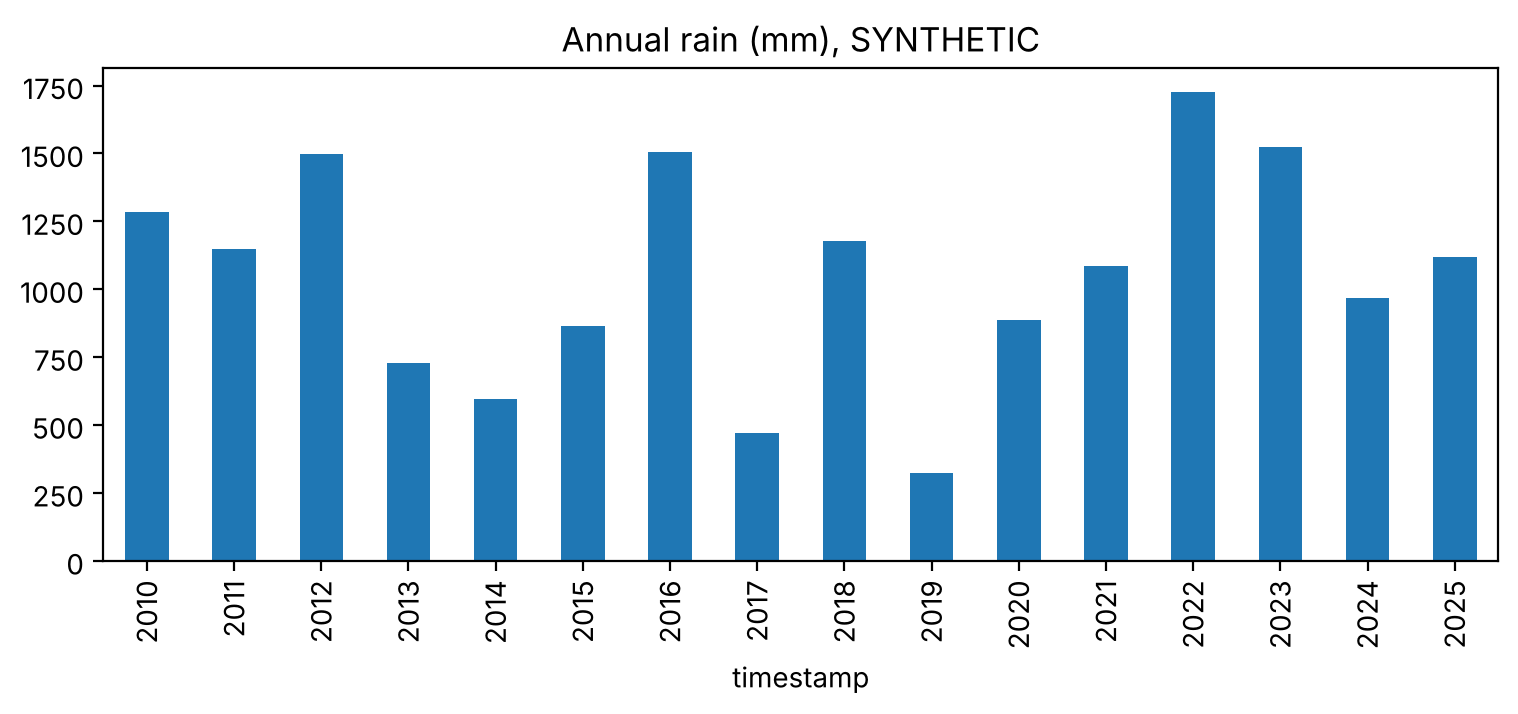

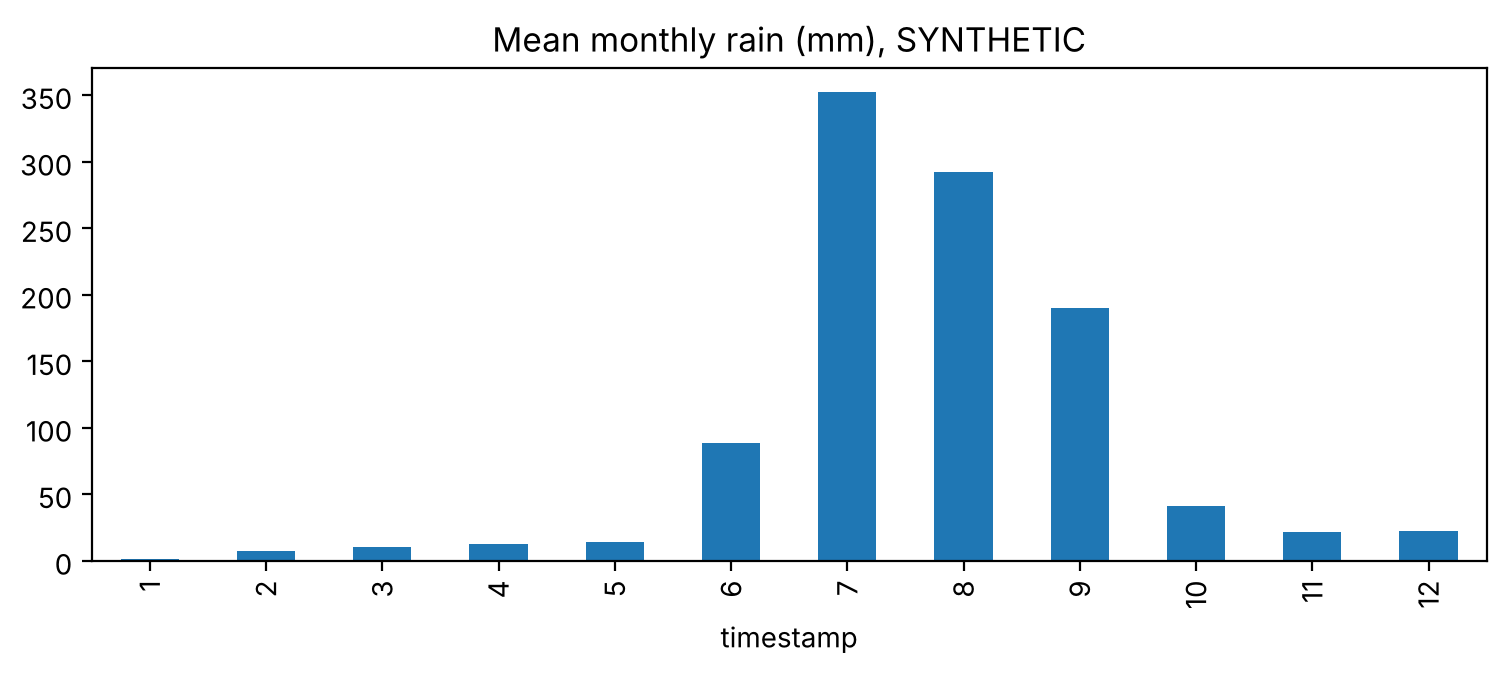

In [3]:
r = df[df.station=='akota'].set_index('timestamp')['rain_mmh']
r.groupby(r.index.year).sum().plot.bar(title='Annual rain (mm), SYNTHETIC')
plt.show()
r.groupby(r.index.month).sum().div(r.index.year.nunique()).plot.bar(title='Mean monthly rain (mm), SYNTHETIC'); plt.show()

## Storm example: rain and level at the three stations

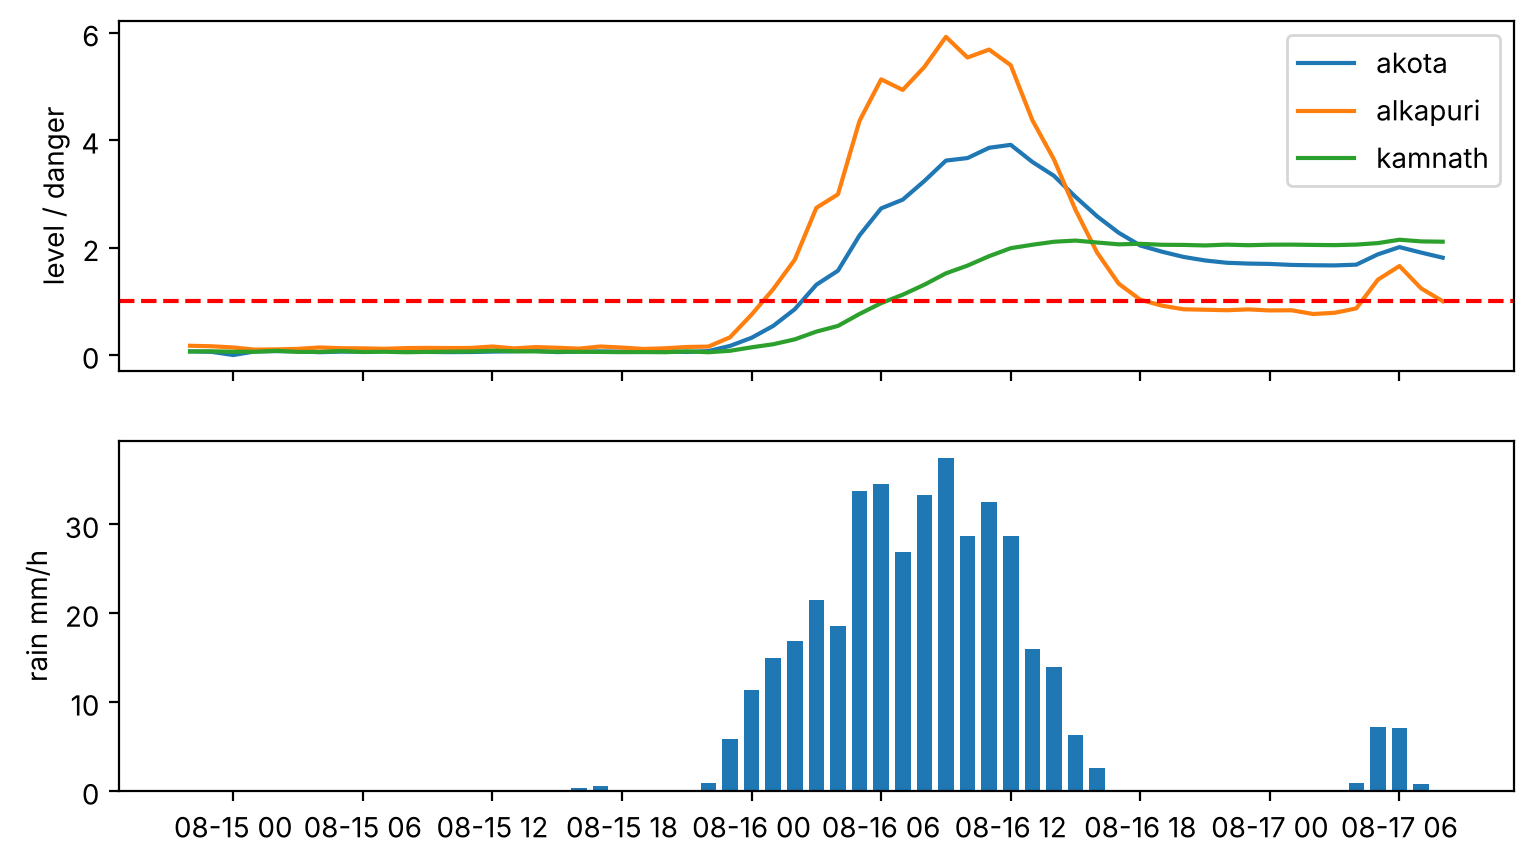

In [4]:
peak = df.loc[df.level_ratio.idxmax()]; t = peak.timestamp
w = df[(df.timestamp>t-pd.Timedelta(hours=36))&(df.timestamp<t+pd.Timedelta(hours=24))]
fig, ax = plt.subplots(2,1, sharex=True, figsize=(9,5))
for s,g in w.groupby('station'): ax[0].plot(g.timestamp, g.level_ratio, label=s)
ax[0].axhline(1, color='r', ls='--'); ax[0].set_ylabel('level / danger'); ax[0].legend()
ax[1].bar(w[w.station=='akota'].timestamp, w[w.station=='akota'].rain_mmh, width=0.03); ax[1].set_ylabel('rain mm/h'); plt.show()

## Class imbalance: flood-within-3h rate

station
akota       0.86
alkapuri    0.73
kamnath     0.87
Name: % rows labelled flood, dtype: float32


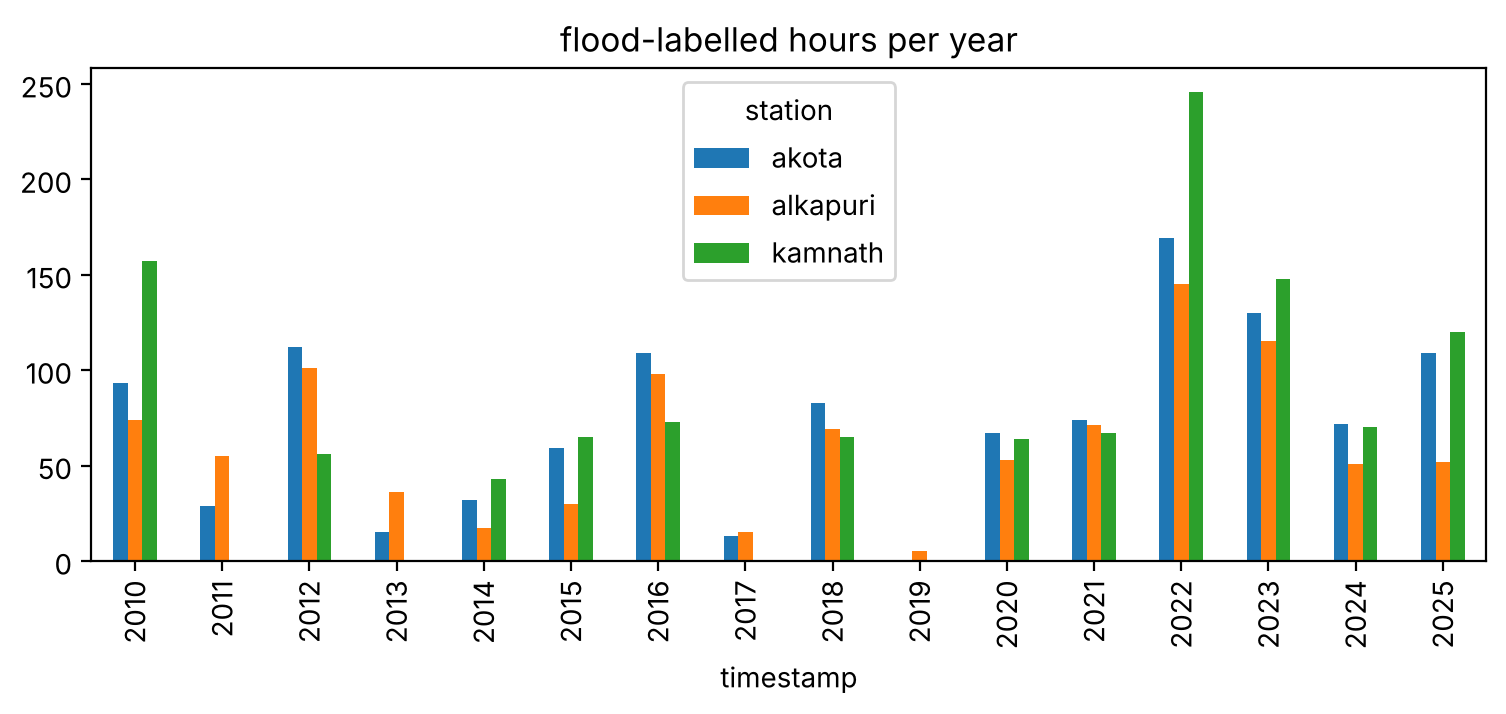

In [5]:
print((df.groupby('station').flood_in_3h.mean()*100).round(2).rename('% rows labelled flood'))
df.groupby([df.timestamp.dt.year,'station']).flood_in_3h.sum().unstack().plot.bar(title='flood-labelled hours per year'); plt.show()

## Feature correlation with +3 h level change

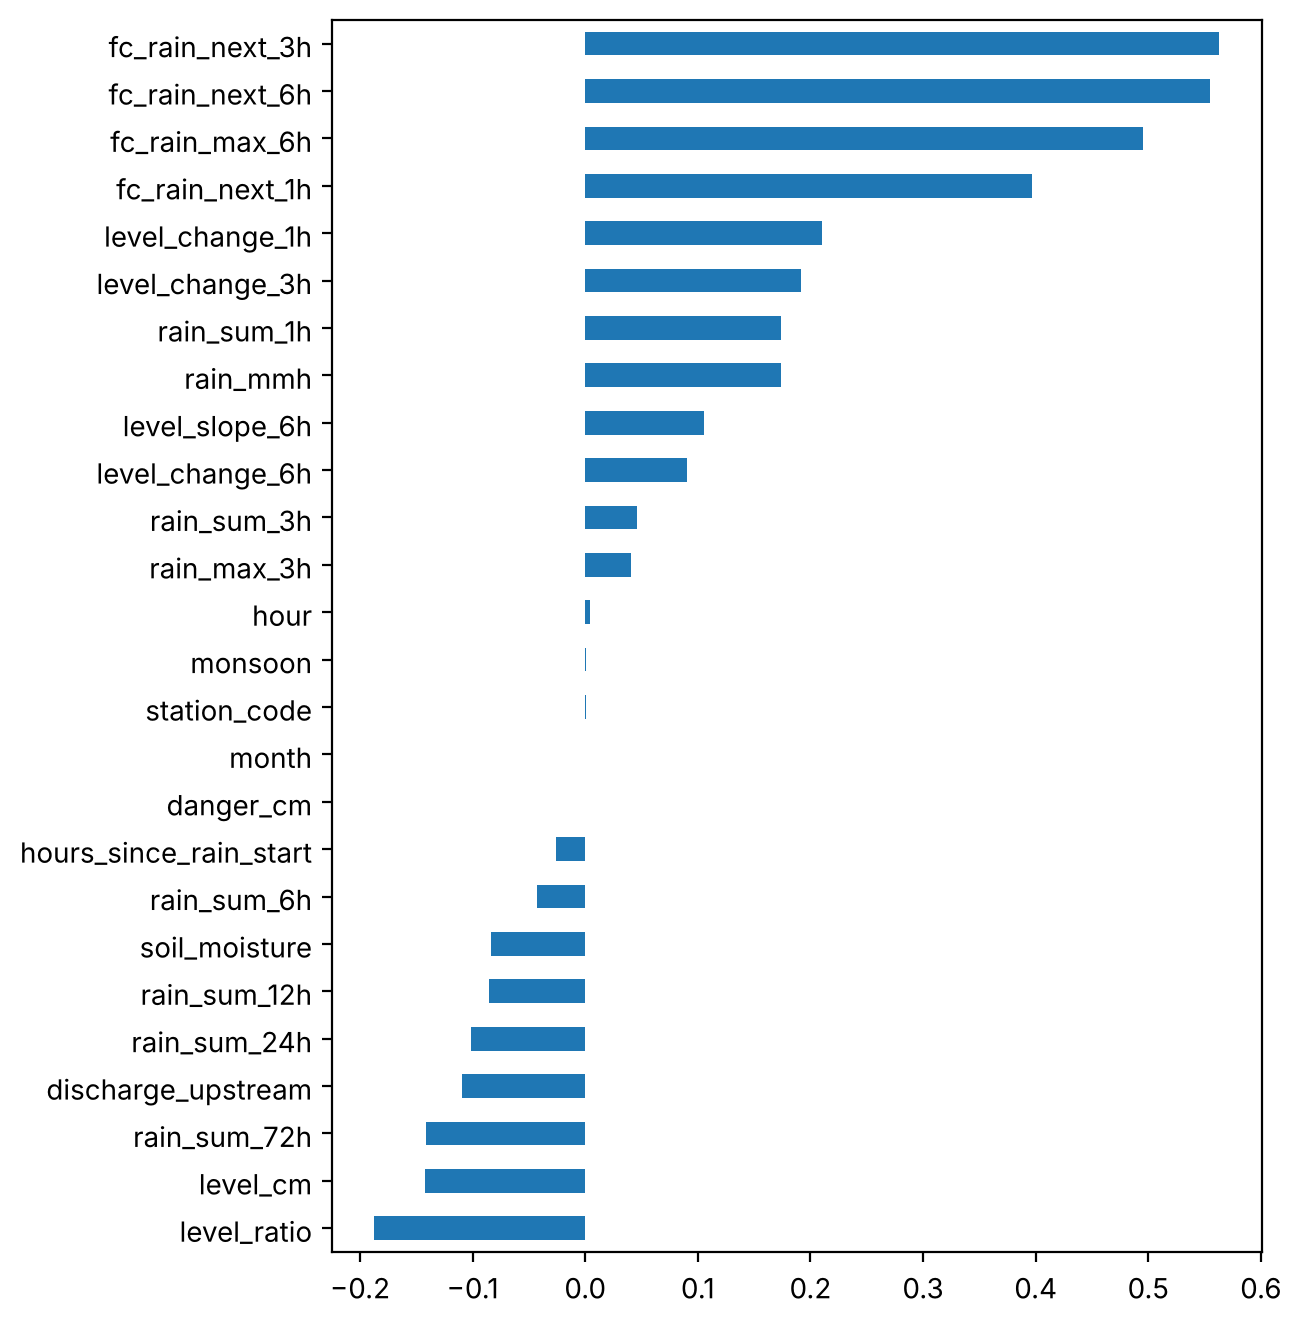

In [6]:
from src.features import FEATURES
d = df.copy(); d['delta3']=d.level_in_3h-d.level_cm
d[FEATURES+['delta3']].corr()['delta3'].drop('delta3').sort_values().plot.barh(figsize=(6,8)); plt.show()

## Model comparison (TEST, exact values from `models/metrics.json`)

In [7]:
m = json.load(open('../models/metrics.json'))
reg = pd.DataFrame({k:{h:v[h]['mae'] for h in v} for k,v in m['regression_test'].items()}).T.round(3); display(reg)
cols=['precision','recall','f1','pr_auc','roc_auc','brier','false_alarm_ratio','detected_events','events','lead_mean_min']
display(pd.DataFrame(m['flood_test']).T[cols])

,1h,2h,3h
Persistence,1.030,1.166,1.302
LinearTrend,1.180,1.520,1.895
LightGBM,0.764,0.808,0.823
RandomForest,0.743,0.791,0.829
GRU (24h window),0.796,0.907,1.004


,precision,recall,f1,pr_auc,roc_auc,brier,false_alarm_ratio,detected_events,events,lead_mean_min
Persistence (levels->flag),0.000000,0.000000,0.000000,0.091011,0.987664,NaN,NaN,0.0,10.0,0.000000
LinearTrend (levels->flag),0.666667,0.466667,0.549020,0.482173,0.992022,NaN,0.333333,8.0,10.0,105.000000
LightGBM (levels->flag),0.777778,0.700000,0.736842,0.797993,0.999067,NaN,0.222222,9.0,10.0,146.666667
RandomForest (levels->flag),0.944444,0.566667,0.708333,0.747422,0.998136,NaN,0.055556,9.0,10.0,126.666667
GRU (levels->flag),0.818182,0.300000,0.439024,0.522448,0.995311,NaN,0.181818,5.0,10.0,108.000000
LightGBM classifier (calibrated),0.717949,0.933333,0.811594,0.886151,0.999840,0.000305,0.282051,10.0,10.0,168.000000
RandomForest classifier (calibrated),0.426471,0.966667,0.591837,0.863910,0.999796,0.000367,0.573529,10.0,10.0,180.000000


## Explainability and error analysis figures

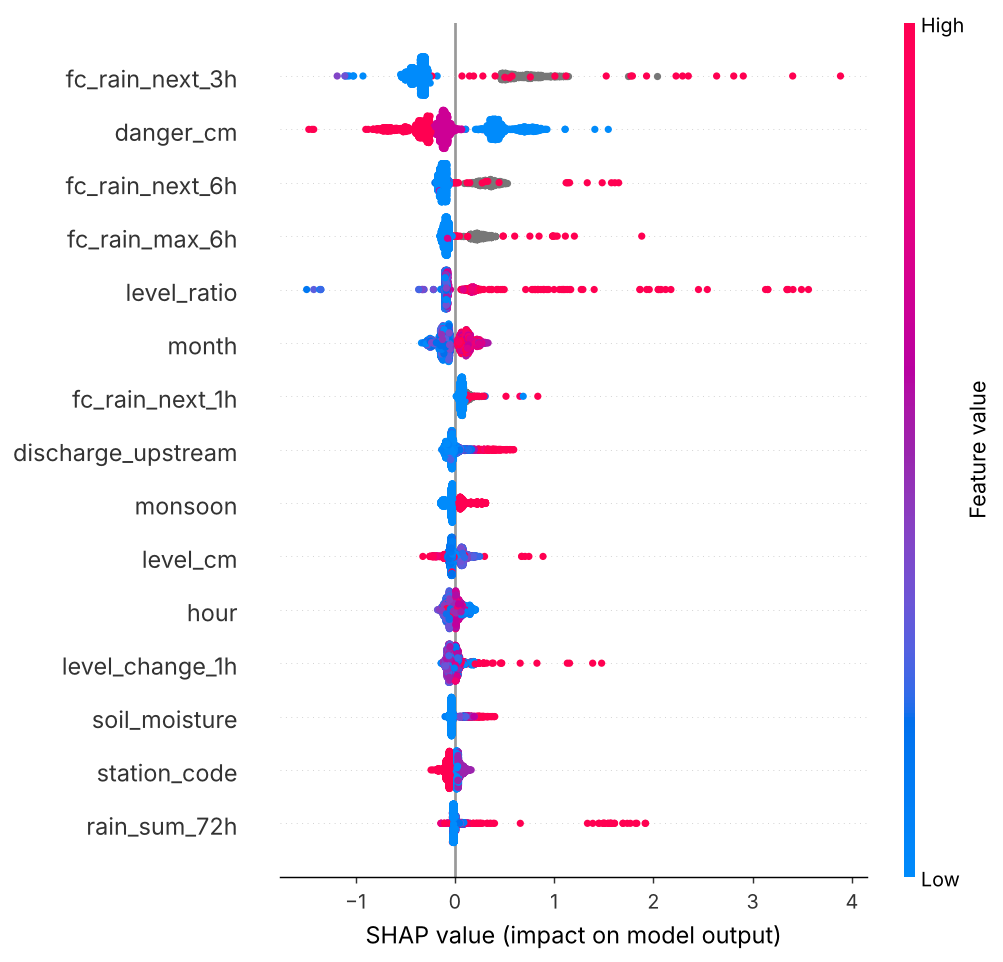

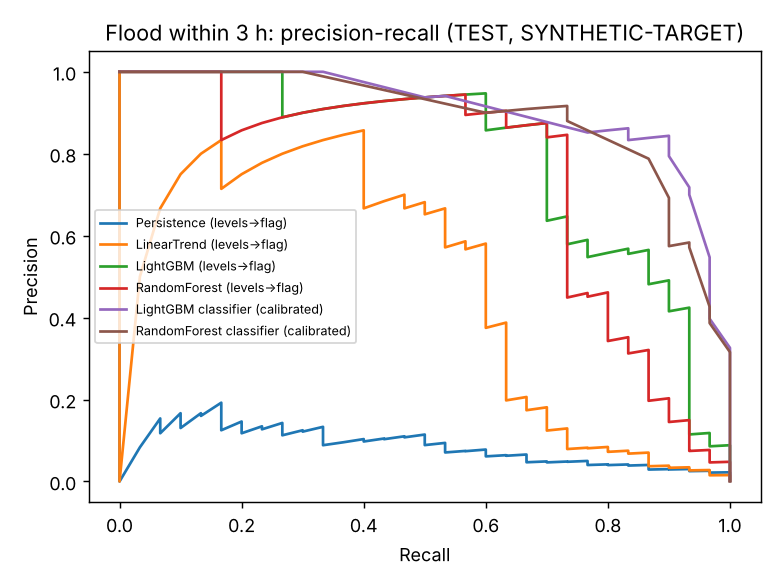

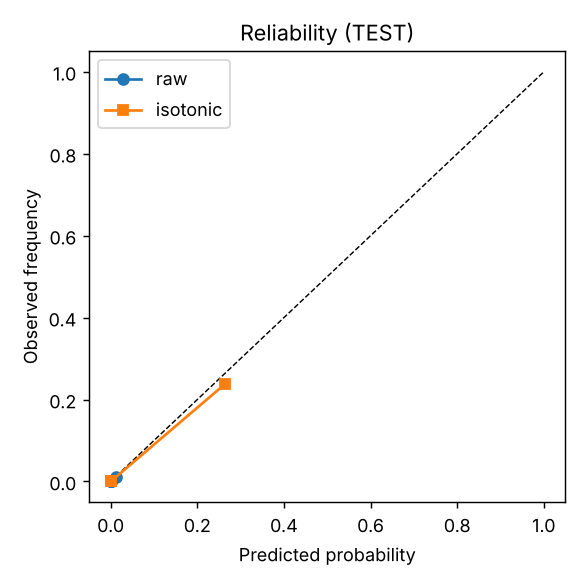

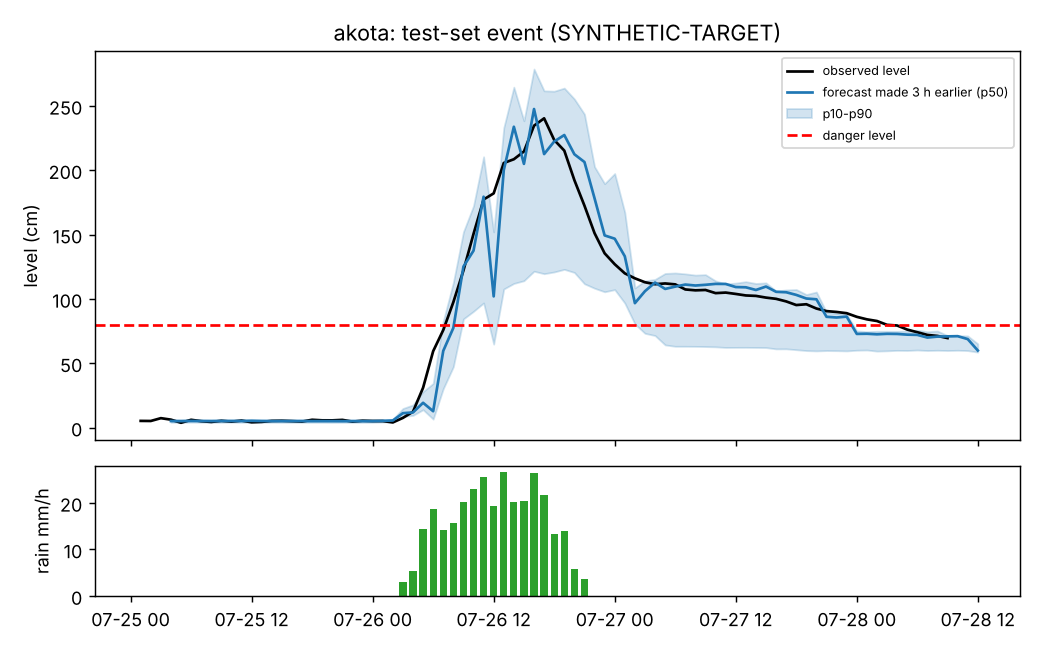

In [8]:
from IPython.display import Image, display
for f in ['shap_summary','pr_curves','reliability','test_event_forecast']: display(Image(f'../docs/figures/{f}.png'))